# Phase 2 — Regime normalization on FD002 and FD004 (12)

Issue #70. The Phase 1 report promised to test regime normalization where it can matter. FD001 runs at a single operating condition, so per-regime scaling and global scaling are the same thing there. FD002 and FD004 run at **six** operating conditions, and the raw sensor values jump whenever the condition changes. Those jumps have nothing to do with wear.

This notebook does three things:

1. **Fixes sensor selection** for multi-regime subsets. Some sensors change only with the operating condition, so they should be dropped once each regime is scaled on its own.
2. **Compares per-regime scaling (6 regimes) with global scaling (1 regime)** for the LSTM (#58) and Hybrid A (#64), on FD002 and FD004, with the 3 engine folds, at seed 42.
3. **Compares the effect with Gupta (2026)**, the preprint that audits exactly this choice.

Everything here is cross-validation on the training engines. The official FD002/FD004 test sets are scored once, after the model freeze, in section 6.

**Terms used below**
- *Regime*: one operating condition (altitude, Mach number, throttle). `RegimeNormalizer` finds the six with k-means on the three operating settings.
- *Per-regime scaling*: each sensor is z-scored with the mean and spread of its own regime. *Global scaling*: one mean and spread for all rows.
- *Selection RMSE*: the RMSE over held-out cycles whose true RUL is at most 130 (`selection.max_true_rul`), the metric every Phase 2 model is tuned on.

In [1]:
from pathlib import Path
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from rul.data.load import load_subset
from rul.evaluation.metrics import evaluate
from rul.evaluation.validation import holm_correction, paired_bootstrap_diff, paired_wilcoxon
from rul.features.cleaning import select_sensors
from rul.features.regimes import RegimeNormalizer
from rul.training.config import apply_overrides, load_config, run_cv
from rul.training.runs import save_cv

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "pyproject.toml").exists())
CACHE = ROOT / "results/models/grids/multi_regime"  # per-run cache (gitignored); delete it to rerun
FIGURES = ROOT / "results/figures"
METRICS = ROOT / "results/metrics"
FIGURES.mkdir(parents=True, exist_ok=True)

SUBSETS = ("FD002", "FD004")
N_REGIMES = 6
MODELS = {"LSTM": "lstm", "Hybrid A": "hybrid_gated"}  # settings tuned on FD001 in #58 and #68
SCALINGS = {"per-regime": N_REGIMES, "global": 1}
K = 130  # selection threshold on true RUL (dl_base.yaml), set by #55

data = {s: load_subset(s, data_dir=ROOT / "data/raw/CMAPSSData").train for s in SUBSETS}
for s, train in data.items():
    print(f"{s}: {train['unit'].nunique()} training engines, {len(train):,} cycles")

FD002: 260 training engines, 53,759 cycles
FD004: 249 training engines, 61,249 cycles


## 1. The sensor-selection fix

`select_sensors` used to judge each sensor over all training rows. On FD002 and FD004 that keeps all 21 sensors, because every sensor moves when the operating condition changes. Four of them (`s_1`, `s_5`, `s_18`, `s_19`) move *only* then: inside each regime they take a single value. After per-regime scaling they are flat (standard deviation under 0.01), so they only add inputs with no signal.

The fix (`rul.features.cleaning.select_sensors(..., regimes=...)`) keeps a sensor only if it varies **within** at least one regime. Every pipeline (`WindowPreprocessor`, `EngineFeatures`, `build_feature_matrices`) now fits the regime normalizer first and passes its labels. With one regime the choice is the same as before, so FD001 keeps its 15 sensors (checked in `tests/test_multi_regime_sensors.py`).

In [2]:
rows = []
for s, train in data.items():
    labels = RegimeNormalizer(N_REGIMES).fit(train).kmeans_.labels_
    before = select_sensors(train)
    after = select_sensors(train, regimes=labels)
    dropped = [c for c in before if c not in after]
    scaled = RegimeNormalizer(N_REGIMES).fit(train).transform(train)
    rows.append({
        "subset": s,
        "regime sizes": np.bincount(labels).tolist(),
        "kept before": len(before),
        "kept after": len(after),
        "dropped": ", ".join(dropped),
        "most values per regime (dropped)": max(train.loc[labels == r, c].nunique() for c in dropped for r in range(N_REGIMES)),
        "std after per-regime scaling (dropped)": float(scaled[dropped].std(ddof=0).max()),
    })
display(pd.DataFrame(rows).set_index("subset"))

,regime sizes,kept before,kept after,dropped,most values per regime (dropped),std after per-regime scaling (dropped)
subset,,,,,,
FD002,"[13458, 8122, 8002, 8044, 8096, 8037]",21,17,"s_1, s_5, s_18, s_19",1,9.786853e-14
FD004,"[15395, 9224, 9139, 9091, 9238, 9162]",21,17,"s_1, s_5, s_18, s_19",1,5.042471e-14


## 2. Per-regime against global scaling

Eight cross-validation runs: two models × two scalings × two subsets. Everything else follows `configs/dl_base.yaml`: cap 125, window 30, the Phase 1 folds (3 folds, seed 42), an engine-level holdout for early stopping, CPU, seed 42. Global scaling is the same pipeline with `inputs.n_regimes=1`, so the two runs differ only in how sensors are scaled (and therefore in which sensors are kept: global scaling keeps all 21).

The model settings were tuned on FD001 and are reused unchanged. Re-tuning on FD002/FD004 is out of scope; both scalings get the same settings, so the comparison stays fair.

Each run is cached with its held-out predictions, so re-running the notebook only retrains missing runs.

In [3]:
def run(subset: str, model: str, scaling: str) -> dict:
    # Cross-validate one setting (or load it from the cache); returns the record plus its predictions.
    name = f"{subset.lower()}_cv_{MODELS[model]}_{scaling.replace('-', '_')}"
    path = CACHE / f"{name}.json"
    if not path.exists():
        config = apply_overrides(
            load_config(ROOT / f"configs/{MODELS[model]}.yaml"),
            [f"subset={subset}", f"inputs.n_regimes={SCALINGS[scaling]}"],
        )
        cv = run_cv(config, data[subset])
        save_cv(name, cv, meta={"name": name, "subset": subset, "scaling": scaling, "config": config}, out_dir=CACHE)
    record = json.loads(path.read_text())
    record["predictions"] = pd.read_csv(CACHE / f"{name}_predictions.csv")
    return record


def stage_rmse(pred: pd.DataFrame) -> dict:
    # Project stages (late <= 50 < mid <= 100 < early) inside the selection band.
    band = pred[pred["rul"] <= K]
    by_stage = evaluate(band["rul"], band["prediction"])["by_stage"]
    return {stage: by_stage[stage]["rmse"] for stage in ("late", "mid", "early")}


def engine_rmse(pred: pd.DataFrame) -> pd.Series:
    # RMSE over each held-out engine's cycles with true RUL <= K (each engine is held out once).
    band = pred[pred["rul"] <= K]
    return ((band["prediction"] - band["rul"]) ** 2).groupby(band["unit"]).mean() ** 0.5


runs = {(s, m, sc): run(s, m, sc) for s in SUBSETS for m in MODELS for sc in SCALINGS}

table = pd.DataFrame([
    {
        "subset": s, "model": m, "scaling": sc,
        "selection RMSE": r["summary"]["selection_rmse"]["mean"],
        "± (folds)": r["summary"]["selection_rmse"]["std"],
        **{f"{k} RMSE": v for k, v in stage_rmse(r["predictions"]).items()},
        "all-cycle RMSE": r["summary"]["rmse"]["mean"],
        "best epochs": [f["best_epoch"] for f in r["folds"]],
        "minutes": r["seconds"] / 60,
    }
    for (s, m, sc), r in runs.items()
]).set_index(["subset", "model", "scaling"])
table.drop(columns="best epochs").round(2).to_csv(METRICS / "fd002_fd004_multi_regime_cv.csv")
display(table.round(2))

selection RMSE  ± (folds)  late RMSE  mid RMSE  \
subset model    scaling                                                      
FD002  LSTM     per-regime           17.51       1.30      12.02     22.27   
                global               18.80       1.59      13.63     22.54   
       Hybrid A per-regime           18.70       1.07      12.70     23.03   
                global               18.30       0.36      12.85     21.98   
FD004  LSTM     per-regime           17.99       1.48      12.21     22.90   
                global               21.20       1.39      17.58     25.52   
       Hybrid A per-regime           18.80       1.86      13.01     22.45   
                global               22.00       1.43      18.43     25.02   

                            early RMSE  all-cycle RMSE   best epochs  minutes  
subset model    scaling                                                        
FD002  LSTM     per-regime       16.49           49.12  [11, 10, 13]     2.39  
                global           19.72           50.06  [32, 23, 58]     5.35  
       Hybrid A per-regime       19.33           48.44     [3, 1, 5]     1.50  
                global           19.42           48.43  [15, 24, 27]     2.93  
FD004  LSTM     per-regime       17.08           77.50  [21, 19, 21]     3.11  
                global           18.88           78.68  [36, 51, 28]     4.92  
       Hybrid A per-regime       20.62           77.09     [7, 9, 2]     1.89  
                global           22.31           78.47  [13, 24, 23]     3.00

`selection RMSE` is the mean over the 3 folds (± its fold standard deviation). The stage columns split the selection band by true RUL: late ≤ 50 < mid ≤ 100 < early ≤ 130. `all-cycle RMSE` includes the long healthy start of each engine, where the capped target (125) is far below the true RUL, so it is much larger and is only shown for completeness.

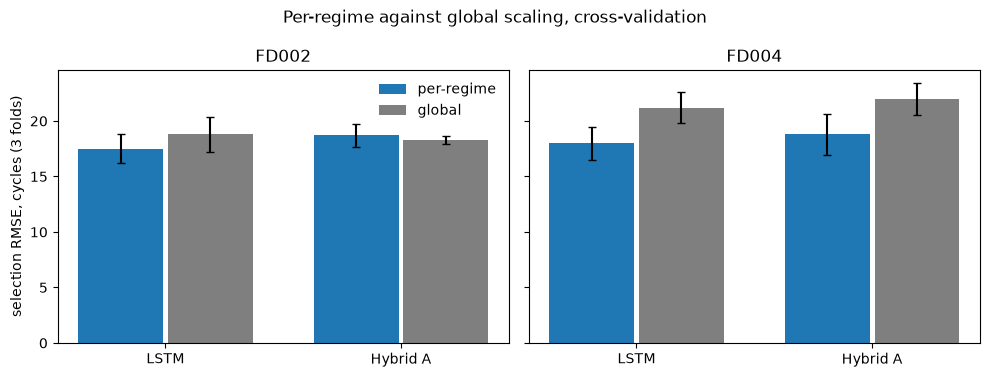

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), sharey=True)
colours = {"per-regime": "tab:blue", "global": "tab:gray"}
for ax, s in zip(axes, SUBSETS):
    for i, m in enumerate(MODELS):
        for j, sc in enumerate(SCALINGS):
            r = table.loc[(s, m, sc)]
            ax.bar(i + (j - 0.5) * 0.38, r["selection RMSE"], 0.36, yerr=r["± (folds)"], capsize=3,
                   color=colours[sc], label=sc if i == 0 else None)
    ax.set_xticks(range(len(MODELS)), list(MODELS))
    ax.set_title(s)
axes[0].set_ylabel("selection RMSE, cycles (3 folds)")
axes[0].legend(frameon=False)
fig.suptitle("Per-regime against global scaling, cross-validation")
fig.tight_layout()
fig.savefig(FIGURES / "fd002_fd004_multi_regime_cv.png", dpi=150)
plt.show()

## 3. Is the difference real?

Each engine is held out exactly once, so both scalings give one error per engine: the RMSE over that engine's cycles in the selection band. The #56 toolkit compares them engine by engine:

- a paired bootstrap 95% CI on the difference in RMSE over engines (per-regime minus global; negative favours per-regime);
- a Wilcoxon signed-rank test on the per-engine errors, Holm-corrected across the four comparisons.

As in notebook 09, the functions are given the per-engine RMSEs against a target of zero, so "RMSE over engines" is the root mean square of the engine RMSEs.

In [5]:
pairs, errors = {}, []
for s in SUBSETS:
    for m in MODELS:
        e_reg = engine_rmse(runs[(s, m, "per-regime")]["predictions"])
        e_glo = engine_rmse(runs[(s, m, "global")]["predictions"]).loc[e_reg.index]
        pairs[f"{s} {m}"] = (e_reg.to_numpy(), e_glo.to_numpy())
        errors.append(pd.DataFrame({"subset": s, "model": m, "unit": e_reg.index,
                                    "per_regime": e_reg.to_numpy(), "global": e_glo.to_numpy()}))
pd.concat(errors).round(3).to_csv(METRICS / "fd002_fd004_multi_regime_engine_errors.csv", index=False)

paired = []
for name, (reg, glo) in pairs.items():
    zeros = np.zeros(len(reg))
    d = paired_bootstrap_diff(zeros, reg, glo)
    w = paired_wilcoxon(zeros, {name: (reg, glo)})[name]
    paired.append({"comparison": name, "engines": len(reg), "RMSE difference": d["difference"],
                   "CI low": d["low"], "CI high": d["high"], "Wilcoxon p": w["p"],
                   "engines better with per-regime": int((reg < glo).sum())})
paired = pd.DataFrame(paired).set_index("comparison")
paired["Holm p"] = holm_correction(paired["Wilcoxon p"].to_numpy())
paired.round(4).to_csv(METRICS / "fd002_fd004_multi_regime_paired.csv")
display(paired.round(4))

,engines,RMSE difference,CI low,CI high,Wilcoxon p,engines better with per-regime,Holm p
comparison,,,,,,,
FD002 LSTM,260,-1.3019,-1.8326,-0.7524,0.000,161,0.0001
FD002 Hybrid A,260,0.4261,-0.7205,1.6678,0.199,139,0.1990
FD004 LSTM,249,-3.2013,-4.0105,-2.3958,0.000,170,0.0000
FD004 Hybrid A,249,-3.1684,-4.3582,-1.9529,0.000,173,0.0000


## 4. Comparison with Gupta (2026)

Gupta (2026), *Auditing Operating-Condition Normalization in C-MAPSS Remaining Useful Life Evaluation* (engrXiv preprint 8145), runs a matched grid on all four subsets: MLP, temporal CNN and LSTM; caps 100, 125 and 150; windows 30 and 50; five matched seeds. Its findings for FD002 and FD004 (Tables 5 and 6):

| | FD002 | FD004 |
|---|---|---|
| Mean paired RMSE change, per-condition minus global (90 matched cells) | −4.39 | −7.40 |
| Cells where per-condition is better | 90 / 90 | 90 / 90 |
| Best configuration (official test RMSE) | LSTM, cap 150, window 50: 22.73 ± 0.28 | LSTM, cap 150, window 50: 21.78 ± 0.11 |

The protocols differ, so only the **direction and rough size** of the effect can be compared now:

- Gupta scores the official test engines at their last cycle; this notebook scores held-out training engines over every cycle in the selection band.
- Gupta uses a fixed 14-sensor set and regimes from rounded operating settings; this project selects sensors from the training fold and finds regimes with k-means.
- Gupta's best FD002/FD004 cells use cap 150 and window 50; this project uses cap 125 and window 30, which #55 and #69 kept.

Section 6 adds this project's official test numbers.

In [6]:
gupta = {"FD002": -4.39, "FD004": -7.40}
compare = pd.DataFrame([
    {"subset": s, "model": m,
     "this project: selection RMSE change (CV)": table.loc[(s, m, "per-regime"), "selection RMSE"] - table.loc[(s, m, "global"), "selection RMSE"],
     "Gupta 2026: mean RMSE change (test, 90 cells)": gupta[s]}
    for s in SUBSETS for m in MODELS
]).set_index(["subset", "model"])
display(compare.round(2))

this project: selection RMSE change (CV)  \
subset model                                                
FD002  LSTM                                         -1.29   
       Hybrid A                                      0.41   
FD004  LSTM                                         -3.21   
       Hybrid A                                     -3.20   

                 Gupta 2026: mean RMSE change (test, 90 cells)  
subset model                                                    
FD002  LSTM                                              -4.39  
       Hybrid A                                          -4.39  
FD004  LSTM                                              -7.40  
       Hybrid A                                          -7.40

## 5. Settings for the official test

For each model, the scaling with the lower mean selection RMSE on each subset goes to the official test in section 6.

In [7]:
chosen = {
    (s, m): min(SCALINGS, key=lambda sc: table.loc[(s, m, sc), "selection RMSE"])
    for s in SUBSETS for m in MODELS
}
chosen_table = pd.Series({f"{s} {m}": sc for (s, m), sc in chosen.items()}, name="chosen scaling")
(METRICS / "fd002_fd004_multi_regime_choice.json").write_text(
    json.dumps({f"{s} {m}": {"scaling": sc, "n_regimes": SCALINGS[sc]} for (s, m), sc in chosen.items()}, indent=2) + "\n"
)
display(chosen_table.to_frame())

,chosen scaling
FD002 LSTM,per-regime
FD002 Hybrid A,global
FD004 LSTM,per-regime
FD004 Hybrid A,per-regime


## 6. Official FD002/FD004 test (after the model freeze)

The tracker (#83) allows one official test run, after the model freeze, and #70 follows the same rule for FD002 and FD004. The freeze is commit `fff9e06`, the same one #71 used for FD001. Each chosen setting from section 5 is refit on all training engines of its subset for the median best epoch of its cross-validation above, at seeds 42, 43 and 44. Each test engine is then scored once, at its last recorded cycle, against the uncapped true RUL.

The cell stops if `src/` or `configs/` differ from the freeze commit, or if a cached cross-validation run no longer matches its config. Once the result files exist, re-running loads them and nothing is trained or scored again.

In [8]:
import subprocess

from rul.evaluation.official import predict_test_cycles, save_results, score_last_cycle
from rul.evaluation.validation import aggregate_seeds
from rul.training.config import run_refit

FREEZE_COMMIT = "fff9e06aad09ba9547388f2db9c9b72e023b400c"  # the model freeze (#83, #71)
TEST_SEEDS = (42, 43, 44)

changed = subprocess.run(["git", "diff", "--name-only", FREEZE_COMMIT, "--", "src", "configs"],
                         cwd=ROOT, capture_output=True, text=True, check=True).stdout.split()
assert not changed, f"changed since the freeze commit: {changed}"

test_results = {}
for (s, m), sc in chosen.items():
    name = f"{s.lower()}_test_{MODELS[m]}_{sc.replace('-', '_')}"
    path = METRICS / f"{name}.json"
    cv_run = runs[(s, m, sc)]
    config = cv_run["meta"]["config"]
    frozen = apply_overrides(load_config(ROOT / f"configs/{MODELS[m]}.yaml"),
                             [f"subset={s}", f"inputs.n_regimes={SCALINGS[sc]}"])
    assert config == frozen, f"cached run for {s} {m} {sc} no longer matches its config"
    if not path.exists():
        _, test, rul_test = load_subset(s, data_dir=ROOT / "data/raw/CMAPSSData")
        scores, preds = [], []
        for seed in TEST_SEEDS:
            seeded = apply_overrides(config, [f"training.seed={seed}"])
            model, _ = run_refit(seeded, data[s], cv_run["median_best_epoch"])
            last, metrics = score_last_cycle(predict_test_cycles(model, test, rul_test))
            scores.append(metrics)
            preds.append(last.assign(seed=seed))
        save_results(name, {"freeze_commit": FREEZE_COMMIT, "seeds": list(TEST_SEEDS), "scaling": sc,
                            "refit_epochs": cv_run["median_best_epoch"],
                            "scored_at": "last recorded cycle of each test engine, against the uncapped true RUL",
                            "per_seed": scores, "summary": aggregate_seeds(scores)}, pd.concat(preds), out_dir=METRICS)
    test_results[(s, m)] = json.loads(path.read_text())

gupta_best = {"FD002": 22.73, "FD004": 21.78}
test_table = pd.DataFrame([
    {"subset": s, "model": m, "scaling": r["scaling"], "test engines": r["per_seed"][0]["n"],
     "RMSE": f"{np.mean([x['rmse'] for x in r['per_seed']]):.2f} ± {np.std([x['rmse'] for x in r['per_seed']], ddof=1):.2f}",
     "MAE": f"{np.mean([x['mae'] for x in r['per_seed']]):.2f}",
     "NASA score": f"{np.mean([x['nasa_score'] for x in r['per_seed']]):.0f}",
     **{f"{st} RMSE": f"{np.mean([x['by_stage'][st]['rmse'] for x in r['per_seed']]):.2f}" for st in ("late", "mid", "early")},
     "Gupta 2026 best (test)": gupta_best[s]}
    for (s, m), r in test_results.items()
]).set_index(["subset", "model"])
test_table.to_csv(METRICS / "fd002_fd004_multi_regime_test.csv")
display(test_table)

scaling  test engines          RMSE    MAE NASA score  \
subset model                                                                
FD002  LSTM      per-regime           259  26.58 ± 0.41  17.92       7927   
       Hybrid A      global           259  27.01 ± 0.80  18.01      10463   
FD004  LSTM      per-regime           248  27.02 ± 0.61  19.65       4993   
       Hybrid A  per-regime           248  26.88 ± 0.34  19.05       5944   

                late RMSE mid RMSE early RMSE  Gupta 2026 best (test)  
subset model                                                           
FD002  LSTM          7.71    20.31      39.72                   22.73  
       Hybrid A      7.04    20.03      40.74                   22.73  
FD004  LSTM          9.44    21.94      37.55                   21.78  
       Hybrid A     11.61    21.13      37.15                   21.78

Most of the test error comes from engines whose true RUL at the last cycle is above the training cap of 125. A model trained with the cap rarely predicts much above 125, so these engines are predicted too early by up to about 70 cycles. The next cell splits each run's error at the cap.

In [9]:
split = []
for (s, m), r in test_results.items():
    name = f"{s.lower()}_test_{MODELS[m]}_{r['scaling'].replace('-', '_')}"
    pred = pd.read_csv(METRICS / f"{name}_predictions.csv")
    pred["error"] = pred["prediction"] - pred["rul"]
    above = pred["rul"] > 125
    rmse = lambda d: d.groupby("seed")["error"].apply(lambda e: np.sqrt(np.mean(e**2))).mean()
    split.append({"subset": s, "model": m, "true RUL max": int(pred["rul"].max()),
                  "share of engines above 125": above.groupby(pred["seed"]).mean().mean(),
                  "RMSE, true RUL <= 125": rmse(pred[~above]), "RMSE, true RUL > 125": rmse(pred[above]),
                  "mean error": pred["error"].mean()})
display(pd.DataFrame(split).set_index(["subset", "model"]).round(2))

true RUL max  share of engines above 125  \
subset model                                                
FD002  LSTM               194                        0.22   
       Hybrid A           194                        0.22   
FD004  LSTM               195                        0.27   
       Hybrid A           195                        0.27   

                 RMSE, true RUL <= 125  RMSE, true RUL > 125  mean error  
subset model                                                              
FD002  LSTM                      14.86                 49.28       -6.96  
       Hybrid A                  14.87                 50.29       -8.21  
FD004  LSTM                      15.62                 45.19       -8.01  
       Hybrid A                  16.86                 43.66       -8.22

## Summary

Sections 1–5 are cross-validation on the training engines, seed 42, with settings tuned on FD001. Section 6 is the one official FD002/FD004 test run, at the freeze commit, with 3 seeds.

- **Sensor fix.** On both subsets, `s_1`, `s_5`, `s_18` and `s_19` take one value inside every regime. They are now dropped (21 → 17 sensors). FD001 keeps its 15.
- **Per-regime scaling helps the LSTM on both subsets.**
  - FD002: selection RMSE 17.51 against 18.80. The per-engine difference is −1.30 cycles (95% CI −1.83 to −0.75, Holm p < 0.001), and per-regime is better on 161 of 260 engines.
  - FD004: 17.99 against 21.20, a difference of −3.20 (CI −4.01 to −2.40, p < 0.001), better on 170 of 249 engines. Most of the FD004 gain is late in life: late-stage RMSE falls from 17.58 to 12.21.
- **Hybrid A: a clear gain on FD004, a null result on FD002.**
  - FD004: 18.80 against 22.00, a difference of −3.17 (CI −4.36 to −1.95, p < 0.001).
  - FD002: 18.70 against 18.30, a difference of +0.43 (CI −0.72 to +1.67, p = 0.20), so no real difference either way.
  - With per-regime inputs the hybrid overfits within 1–5 epochs: training loss falls to about a third of the global run's while held-out error rises. Early stopping catches it, but the per-regime hybrid probably needs stronger regularization (#66).
- **Agreement with Gupta (2026).**
  - Same direction: per-regime scaling is better wherever there's a real difference, and the effect is larger on FD004 than on FD002 (here −3.2 against −1.3 for the LSTM; Gupta −7.40 against −4.39).
  - Our effects are smaller. Gupta scores the official test engines at their last cycle, keeps a fixed 14-sensor set and uses other caps and windows. We score held-out training engines over the whole selection band.
  - On the official test, our best runs are about 4–5 cycles worse than Gupta's best configurations (26.6 against 22.73 on FD002, 26.9 against 21.78 on FD004). Gupta's best cells use cap 150 and window 50; ours use the FD001 settings, cap 125 and window 30. The split above points to the cap as the main source: on engines whose true RUL is at most 125, RMSE is 14.9–16.9, and on the 22–27% above it, 44–50. This is the likely main cause, not a tested one: a cap of 150 was not run here.
- **For the official test:** per-regime scaling for the LSTM on both subsets and for Hybrid A on FD004. On FD002 the rule picks global scaling for Hybrid A, by a difference that is within noise.
- **Official test (section 6), mean ± s.d. over seeds 42–44:**
  - FD002: LSTM per-regime 26.58 ± 0.41, Hybrid A global 27.01 ± 0.80.
  - FD004: LSTM per-regime 27.02 ± 0.61, Hybrid A per-regime 26.88 ± 0.34.
  - The two models are within half a cycle of each other on both subsets, about the seed spread. Every run predicts early on average (mean error −7 to −8 cycles), because of the engines above the cap.
  - Only the chosen scaling was scored, so the test does not repeat the per-regime against global comparison. That comparison rests on the cross-validation above.
- **Limits:** cross-validation used one seed, and every setting was tuned on FD001, not on FD002 or FD004.